# 01 – Build the Batch Master Table

**Run this notebook only when the pulled data changes** (after `python pull_data.py`).
It reads the pulled sensor data and the real lab samples, builds the tables and saves them to `data/`:

| File | 1 row = | Used by |
|---|---|---|
| `data/batch_master.csv` | 1 batch | `02_analysis.ipynb`, Excel |
| `data/lab_linked.csv` | 1 real lab sample (with its digester and batch) | `02_analysis.ipynb` |

Sections 3–6 are **checks**: look at them before trusting the analysis. No PI access in this notebook.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

from pull_data import load_data
from lab import load_lab_samples
from build_master import build_master, save_outputs

## 1. Load the pulled sensor data and the real lab samples

In [2]:
df = load_data(config.data_name())
print("Sensor data:", df.shape, df.index.min(), "->", df.index.max())

lab = load_lab_samples(refresh=True)   # refresh=True re-reads the log book Excel files
print("Lab samples:", len(lab), lab.index.min(), "->", lab.index.max())

Sensor data: (29089, 127) 2026-07-01 00:00:00 -> 2026-10-10 00:00:00
Reading 1.LINE NO.2_Log Sheet_2025 in JAN 2026.xlsx
Reading 2.LINE NO.2_Log Sheet_2026 in FEB 2026.xlsx
Reading 3.LINE NO.2_Log Sheet_2026 in march 2026.xlsx
Reading 4.LINE NO.2_Log Sheet_2026 in APR 2026.xlsx
Reading 5.LINE NO.2_Log Sheet_2026 in MAY 2026.xlsx
Reading 6.LINE NO.2_Log Sheet_ in JUN 2026 Rev.01.xlsx
Reading 7.LINE NO.2_Log Sheet_ in JUL 2026.xlsx
Reading 8.LINE NO.2_Log Sheet_ in Aug 2026.xlsx
Reading 09. LINE NO.2_Log Sheet_ in Sep 2026.xlsx
Reading 10. LINE NO.2_Log Sheet_ in Oct 2026.xlsx.48024.1793087877.tmp
Lab samples: 2722 2026-01-01 08:00:00 -> 2026-10-27 12:00:00


## 2. Build and save the tables

In [3]:
master, phases, lab_linked, phases_summary, phases_summary_lab = build_master(df, lab)
save_outputs(master, lab_linked, phases_summary, phases_summary_lab)
print(f"\nBatch Master Table: {master.shape[0]} batches x {master.shape[1]} columns")
print(f"Phase Summary Table: {phases_summary.shape[0]} phase runs x {phases_summary.shape[1]} columns")
print(f"Phase Summary (with lab): {phases_summary_lab.shape[0]} phase runs x {phases_summary_lab.shape[1]} columns")
master.head()

d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\lab.py:55: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table.insert(0, lab_column, values)


Saved 1540 batches    -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\batch_master.csv
Saved 1833 lab rows -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\lab_linked.csv
Saved 10223 phase runs -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\phase_summary.csv
Saved 10223 phase runs (with lab) -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\phase_summary_with_lab.csv

Batch Master Table: 1540 batches x 76 columns
Phase Summary Table: 10223 phase runs x 121 columns
Phase Summary (with lab): 10223 phase runs x 129 columns


,digester,batch_id,batch_number,batch_start,batch_end,batch_hours,chip_filling_start,chip_filling_end,chip_filling_minutes,prehydrolysis_start,prehydrolysis_end,prehydrolysis_minutes,hot_liquor_filling_start,hot_liquor_filling_end,hot_liquor_filling_minutes,heat_and_cook_start,heat_and_cook_end,heat_and_cook_minutes,displacement_start,displacement_end,displacement_minutes,discharge_start,discharge_end,discharge_minutes,wait_start,wait_end,wait_minutes,unknown_phase_count,h_factor,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait,chip_weight_max_chip_filling,ventilation_temp_max_chip_filling,pfactor_actual_last_prehydrolysis,pfactor_setpoint_last_prehydrolysis,digester_pressure_max_prehydrolysis,steam_to_heater_flow_mean_prehydrolysis,chip_weight_max_hot_liquor_filling,circulation_temp_max_hot_liquor_filling,white_liquor_dosing_flow_mean_hot_liquor_filling,alkali_accumulator1_conc_mean_hot_liquor_filling,alkali_accumulator2_conc_mean_hot_liquor_filling,hbl_accumulator_cond_mean_hot_liquor_filling,circulation_temp_max_heat_and_cook,circulation_temp_mean_heat_and_cook,bottom_circulation_temp_mean_heat_and_cook,digester_pressure_mean_heat_and_cook,steam_to_heater_flow_mean_heat_and_cook,LP_pressure_mean_heat_and_cook,steam_heater_temp_max_heat_and_cook,screen_diff_pressure_mean_heat_and_cook,circulation_pump_current_mean_heat_and_cook,displacement_liquor_temp_mean_displacement,black_liquor_conductivity_mean_displacement,liquor_to_wood_ratio,white_liquor_m3,white_liquor_per_ton_chip,pfactor_gap,press1_kappa,press1_kappa_samples,press1_kappa_first_time,press1_viscosity,press1_viscosity_samples,press1_viscosity_first_time,press1_brightness,press1_brightness_samples,press1_brightness_first_time,kappa_grade,viscosity_grade,overall_grade,quality_flag
0,1,1,8474,2026-07-01 02:35:00,2026-07-01 07:10:00,4.583333,2026-07-01 02:35:00,2026-07-01 03:10:00,35.0,2026-07-01 03:15:00,2026-07-01 04:25:00,70.0,2026-07-01 04:30:00,2026-07-01 05:40:00,70.0,2026-07-01 05:45:00,2026-07-01 06:20:00,35.0,2026-07-01 06:25:00,2026-07-01 06:55:00,30.0,2026-07-01 07:00:00,2026-07-01 07:10:00,10.0,NaT,NaT,NaN,0,498.851470,0.076499,0.153010,268.062758,158.551527,72.237184,0.028959,NaN,91.981812,90.0,321.038391,340.0,8.399415,2.287810,234.540176,166.027649,12.228516,37.229941,14.235819,-7.220161,155.967484,153.834597,158.713554,6.237671,4.698055,6.576709,162.679688,-1.875,64.285583,142.968742,48.976562,1.549854,14.266602,0.155102,-18.961609,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaN,ok
1,1,2,8477,2026-07-01 07:15:00,2026-07-01 11:50:00,4.583333,2026-07-01 07:15:00,2026-07-01 07:50:00,35.0,2026-07-01 07:55:00,2026-07-01 09:05:00,70.0,2026-07-01 09:10:00,2026-07-01 10:15:00,65.0,2026-07-01 10:20:00,2026-07-01 11:00:00,40.0,2026-07-01 11:05:00,2026-07-01 11:35:00,30.0,2026-07-01 11:40:00,2026-07-01 11:50:00,10.0,NaT,NaT,NaN,0,500.930686,0.077393,0.145778,255.445761,167.321519,78.163406,0.035133,NaN,93.422852,90.0,311.747467,340.0,8.247070,3.616888,234.994949,165.575516,12.228516,37.247061,14.226827,-7.192894,157.266037,152.380047,156.912455,6.191016,2.674360,6.521875,163.429688,-1.875,62.159804,135.249460,48.976562,1.515390,13.247559,0.141802,-28.252533,NaN,NaN,NaT,NaN,NaN,NaT,35.6,1.0,2026-07-01 14:00:00,NaN,NaN,NaN,ok
2,1,3,8480,2026-07-01 11:55:00,2026-07-01 17:05:00,5.166667,2026-07-01 11:55:00,2026-07-01 12:30:00,35.0,2026-07-01 12:35:00,2026-07-01 13:40:00,65.0,2026-07-01 13:45:00,2026-07-01 15:05:00,80.0,2026-07-01 15:10:00,2026-07-01 15:45:00,35.0,2026-07-01 15:50:00,2026-07-01 16:20:00,30.0,2026-07-01 16:25:00,2026-07-01 17:05:00,40.0,NaT,NaT,NaN,0,579.728917,0.124772,0.201287,347.965924,157.434756,74.328237,0.086866,NaN,92.505829,90.0,323.886993,340.0,8.595118,9.361931,235.435364,167.981445,12.228516,37.210162,14.355130,-7.298068,156.054688,153.653730,157.859575,5.964283,-5.838564,6.304126,163.085938,-1.875,71.539513,135.933633,48.976562,1.545087,16.304688,0.176256,-16.113007,NaN,NaN,NaT,NaN,NaN,NaT

## 3. Check – quality flags

`ok` = normal batch. Other flags (nothing is removed, `02_analysis` uses only `ok` by default):
- `missing_phase` – no HEAT&COOK or no DISCHARGE (sequence broken, or cut at the start/end of the data)
- `unknown_phase` – phase text that is not a real phase (e.g. "8", "0" = PI system states)
- `long_batch` – longer than `config.LONG_BATCH_HOURS` (probably includes a stop)
- `no_h_factor` – H-factor missing or 0

In [4]:
display(pd.crosstab(master["quality_flag"], master["digester"], margins=True))

digester,1,2,3,4,All
quality_flag,,,,,
long_batch,7,6,7,31,51
missing_phase,1,1,1,0,3
missing_phase;no_h_factor,3,1,2,4,10
ok,413,414,408,228,1463
unknown_phase,3,2,5,2,12
unknown_phase;long_batch,0,1,0,0,1
All,427,425,423,265,1540


## 4. Check – in which phase does the cooking (H-factor) happen?

Median H-factor added in each phase per batch (only `ok` batches).
`h_factor` = sum of the phases in `config.H_FACTOR_PHASES`.
If a phase outside `H_FACTOR_PHASES` has a large H, the H-factor window may be wrong.
**D4**: its temperature tag (`TI423`) behaves differently (high H during PREHYDRAU) – D4 is provisional.

In [5]:
ok = master[master["quality_flag"] == "ok"]
h_cols = [f"h_{s}" for s in config.PHASE_NAMES.values() if f"h_{s}" in master]
display(ok.groupby("digester")[h_cols + ["h_factor"]].median().round(1))

share = ok[h_cols].div(ok[h_cols].sum(axis=1), axis=0) * 100
print("Share of the total H in each phase (% , median):")
display(share.groupby(ok["digester"]).median().round(1))

,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait,h_factor
digester,,,,,,,,
1,0.1,0.3,258.6,159.4,86.1,0.1,0.1,511.4
2,0.1,0.2,68.3,167.6,91.1,0.1,0.1,329.7
3,0.1,0.2,44.0,167.8,84.7,0.1,0.1,301.8
4,0.1,585.3,148.4,170.1,73.9,0.1,0.1,397.8


Share of the total H in each phase (% , median):


,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait
digester,,,,,,,
1,0.0,0.1,51.2,31.3,16.9,0.0,0.0
2,0.0,0.1,20.9,49.9,27.6,0.0,0.0
3,0.0,0.1,14.4,55.9,28.2,0.0,0.0
4,0.0,56.2,15.9,17.1,8.2,0.0,0.0


## 5. Check – temperature profile of example batches

Red = circulation temperature (used for H-factor), dark red dashed = bottom circulation, blue = pressure.
Coloured bands = phases. Change `EXAMPLE_FROM` to look at other days.

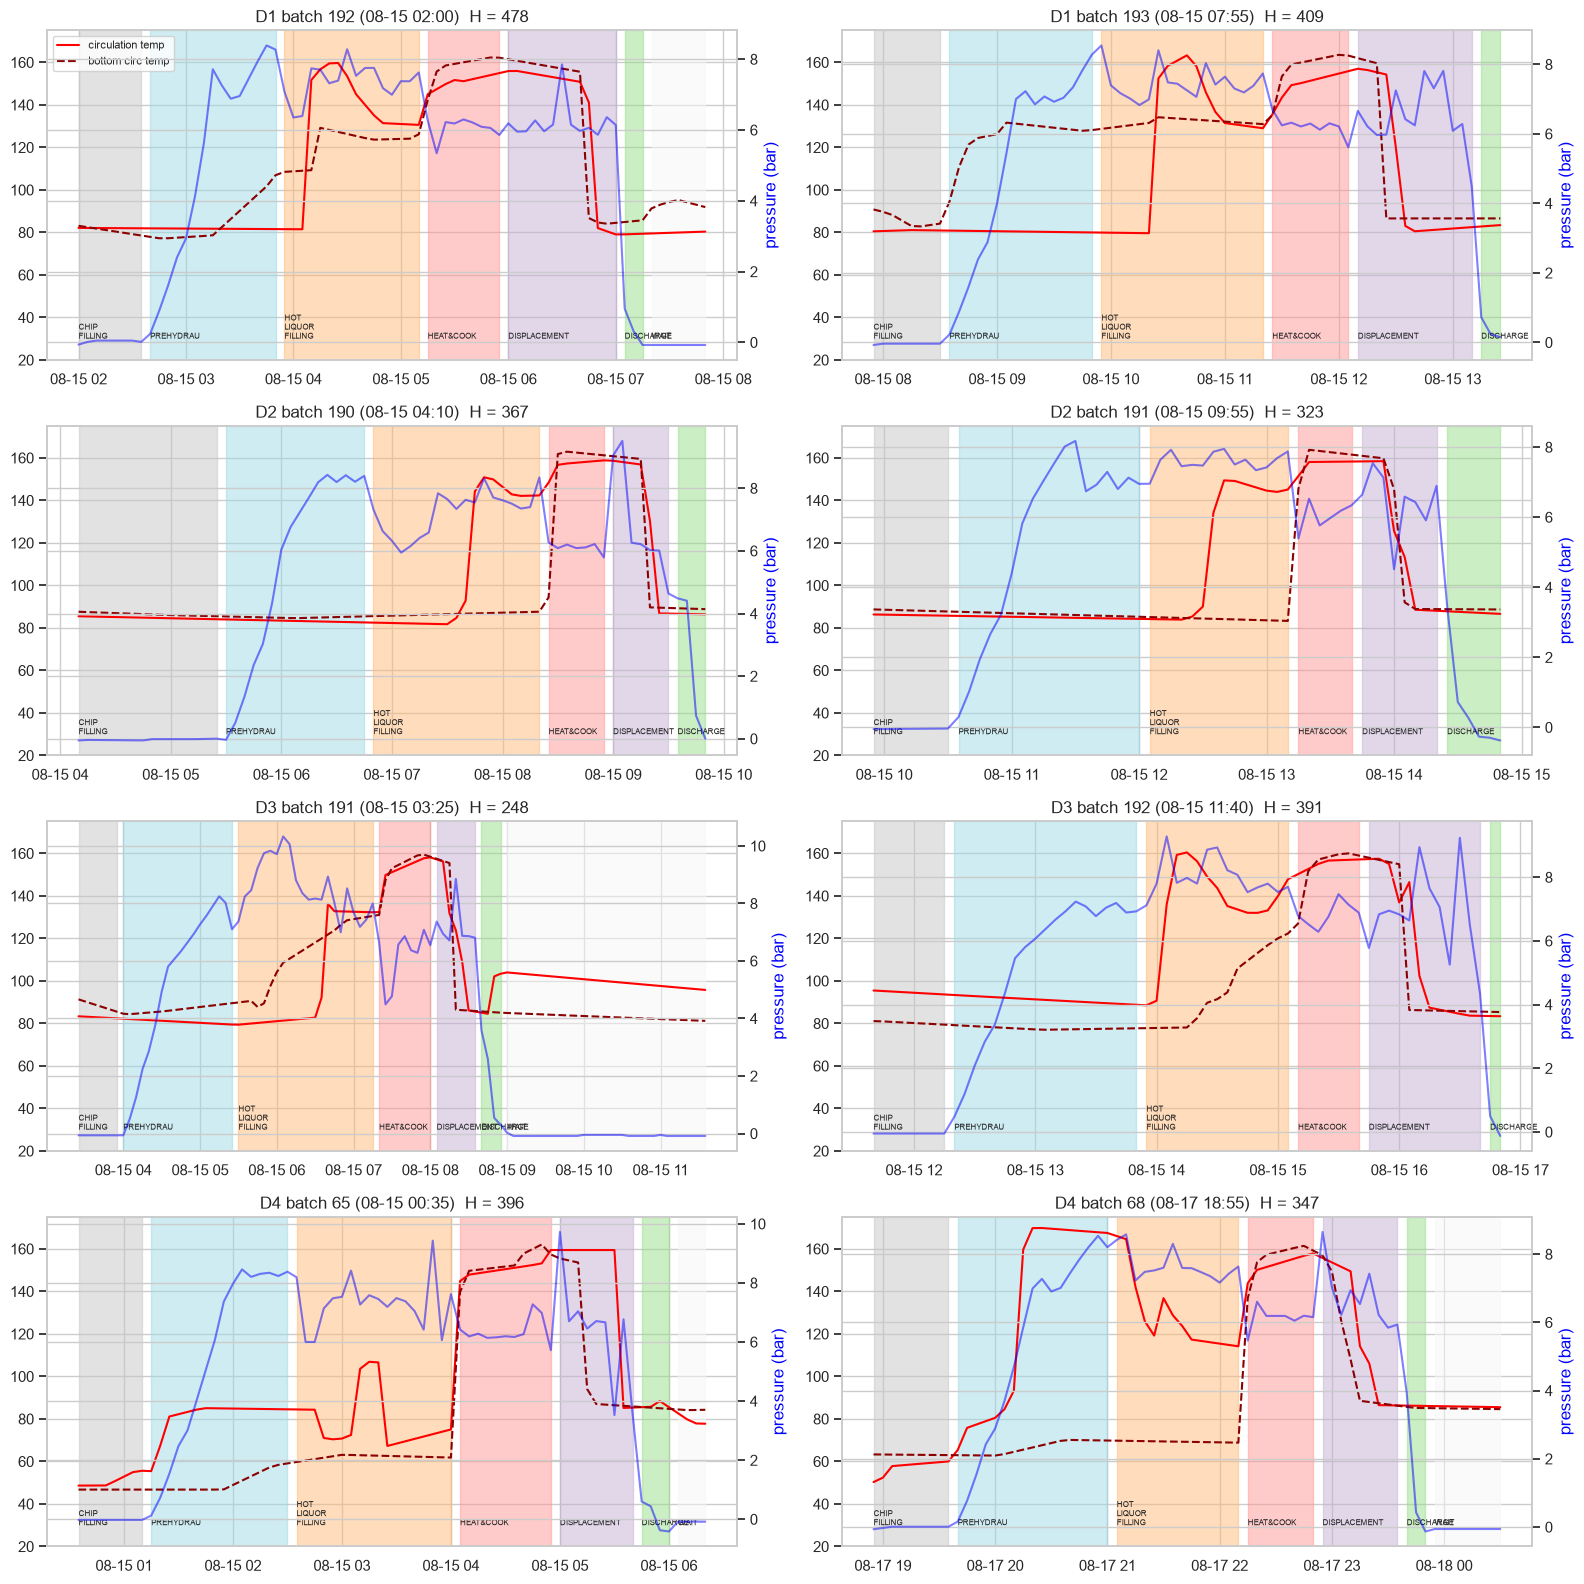

In [6]:
EXAMPLE_FROM = "2026-08-15"
PHASE_COLORS = {"CHIP FILLING": "#c7c7c7", "PREHYDRAU": "#9edae5", "HOT LIQUOR FILLING": "#ffbb78",
                "HEAT&COOK": "#ff9896", "DISPLACEMENT": "#c5b0d5", "DISCHARGE": "#98df8a", "WAIT": "#f7f7f7"}

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
for row, dig in enumerate([1, 2, 3, 4]):
    examples = ok[(ok["digester"] == dig) & (ok["batch_start"] >= EXAMPLE_FROM)].head(2)
    for col, (_, b) in enumerate(examples.iterrows()):
        ax = axes[row, col]
        part = df.loc[b["batch_start"]:b["batch_end"]]
        ax.plot(part.index, part[f"D{dig}_circulation_temp"], color="red", label="circulation temp")
        ax.plot(part.index, part[f"D{dig}_bottom_circulation_temp"], color="darkred", linestyle="--", label="bottom circ temp")
        ax2 = ax.twinx()
        ax2.plot(part.index, part[f"D{dig}_digester_pressure"], color="blue", alpha=0.5)
        ax2.set_ylabel("pressure (bar)", color="blue")
        for p in phases[(phases["digester"] == dig) & (phases["batch_id"] == b["batch_id"])].itertuples():
            ax.axvspan(p.start, p.end, color=PHASE_COLORS.get(p.phase, "yellow"), alpha=0.5)
            ax.text(p.start, 30, p.phase.replace(" ", "\n"), fontsize=6)
        ax.set_ylim(20, 175)
        ax.set_title(f"D{dig} batch {b['batch_id']} ({b['batch_start']:%m-%d %H:%M})  H = {b['h_factor']:.0f}")
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 6. Check – lab samples linked to a batch

Lab time → digester at Press 1 (`Dk_press1_status == k`) → that digester's latest batch discharged before the sample.
Samples with no single digester at Press 1 are not linked.

In [7]:
print("Real lab samples with a digester, and how many were linked to a batch:")
display(lab_linked.groupby(["parameter", "digester"])["batch_id"].agg(samples="size", linked="count").unstack("digester"))

print("Batches that have a Kappa value:", master["press1_kappa"].notna().sum(), "of", len(master))

Real lab samples with a digester, and how many were linked to a batch:


samples                linked               
digester                1    2    3    4      1    2    3    4
parameter                                                     
press1_brightness     201  236  272  185    198  235  272  184
press1_kappa          117  127  133   94    114  127  133   93
press1_viscosity      114  128  132   94    111  128  132   93

Batches that have a Kappa value: 466 of 1540


**Next:** open `02_analysis.ipynb` (it only reads the saved CSV files).